<a href="https://colab.research.google.com/github/OJB-Quantum/Notebooks-for-Ideas/blob/main/ST_FMR_Tree_Visualization_in_Colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Authored by Onri Jay Benally (2026)

Open Access (CC-BY-4.0)

Using Python 3.13.16 environment at: /usr
Checked 2 packages in 127ms


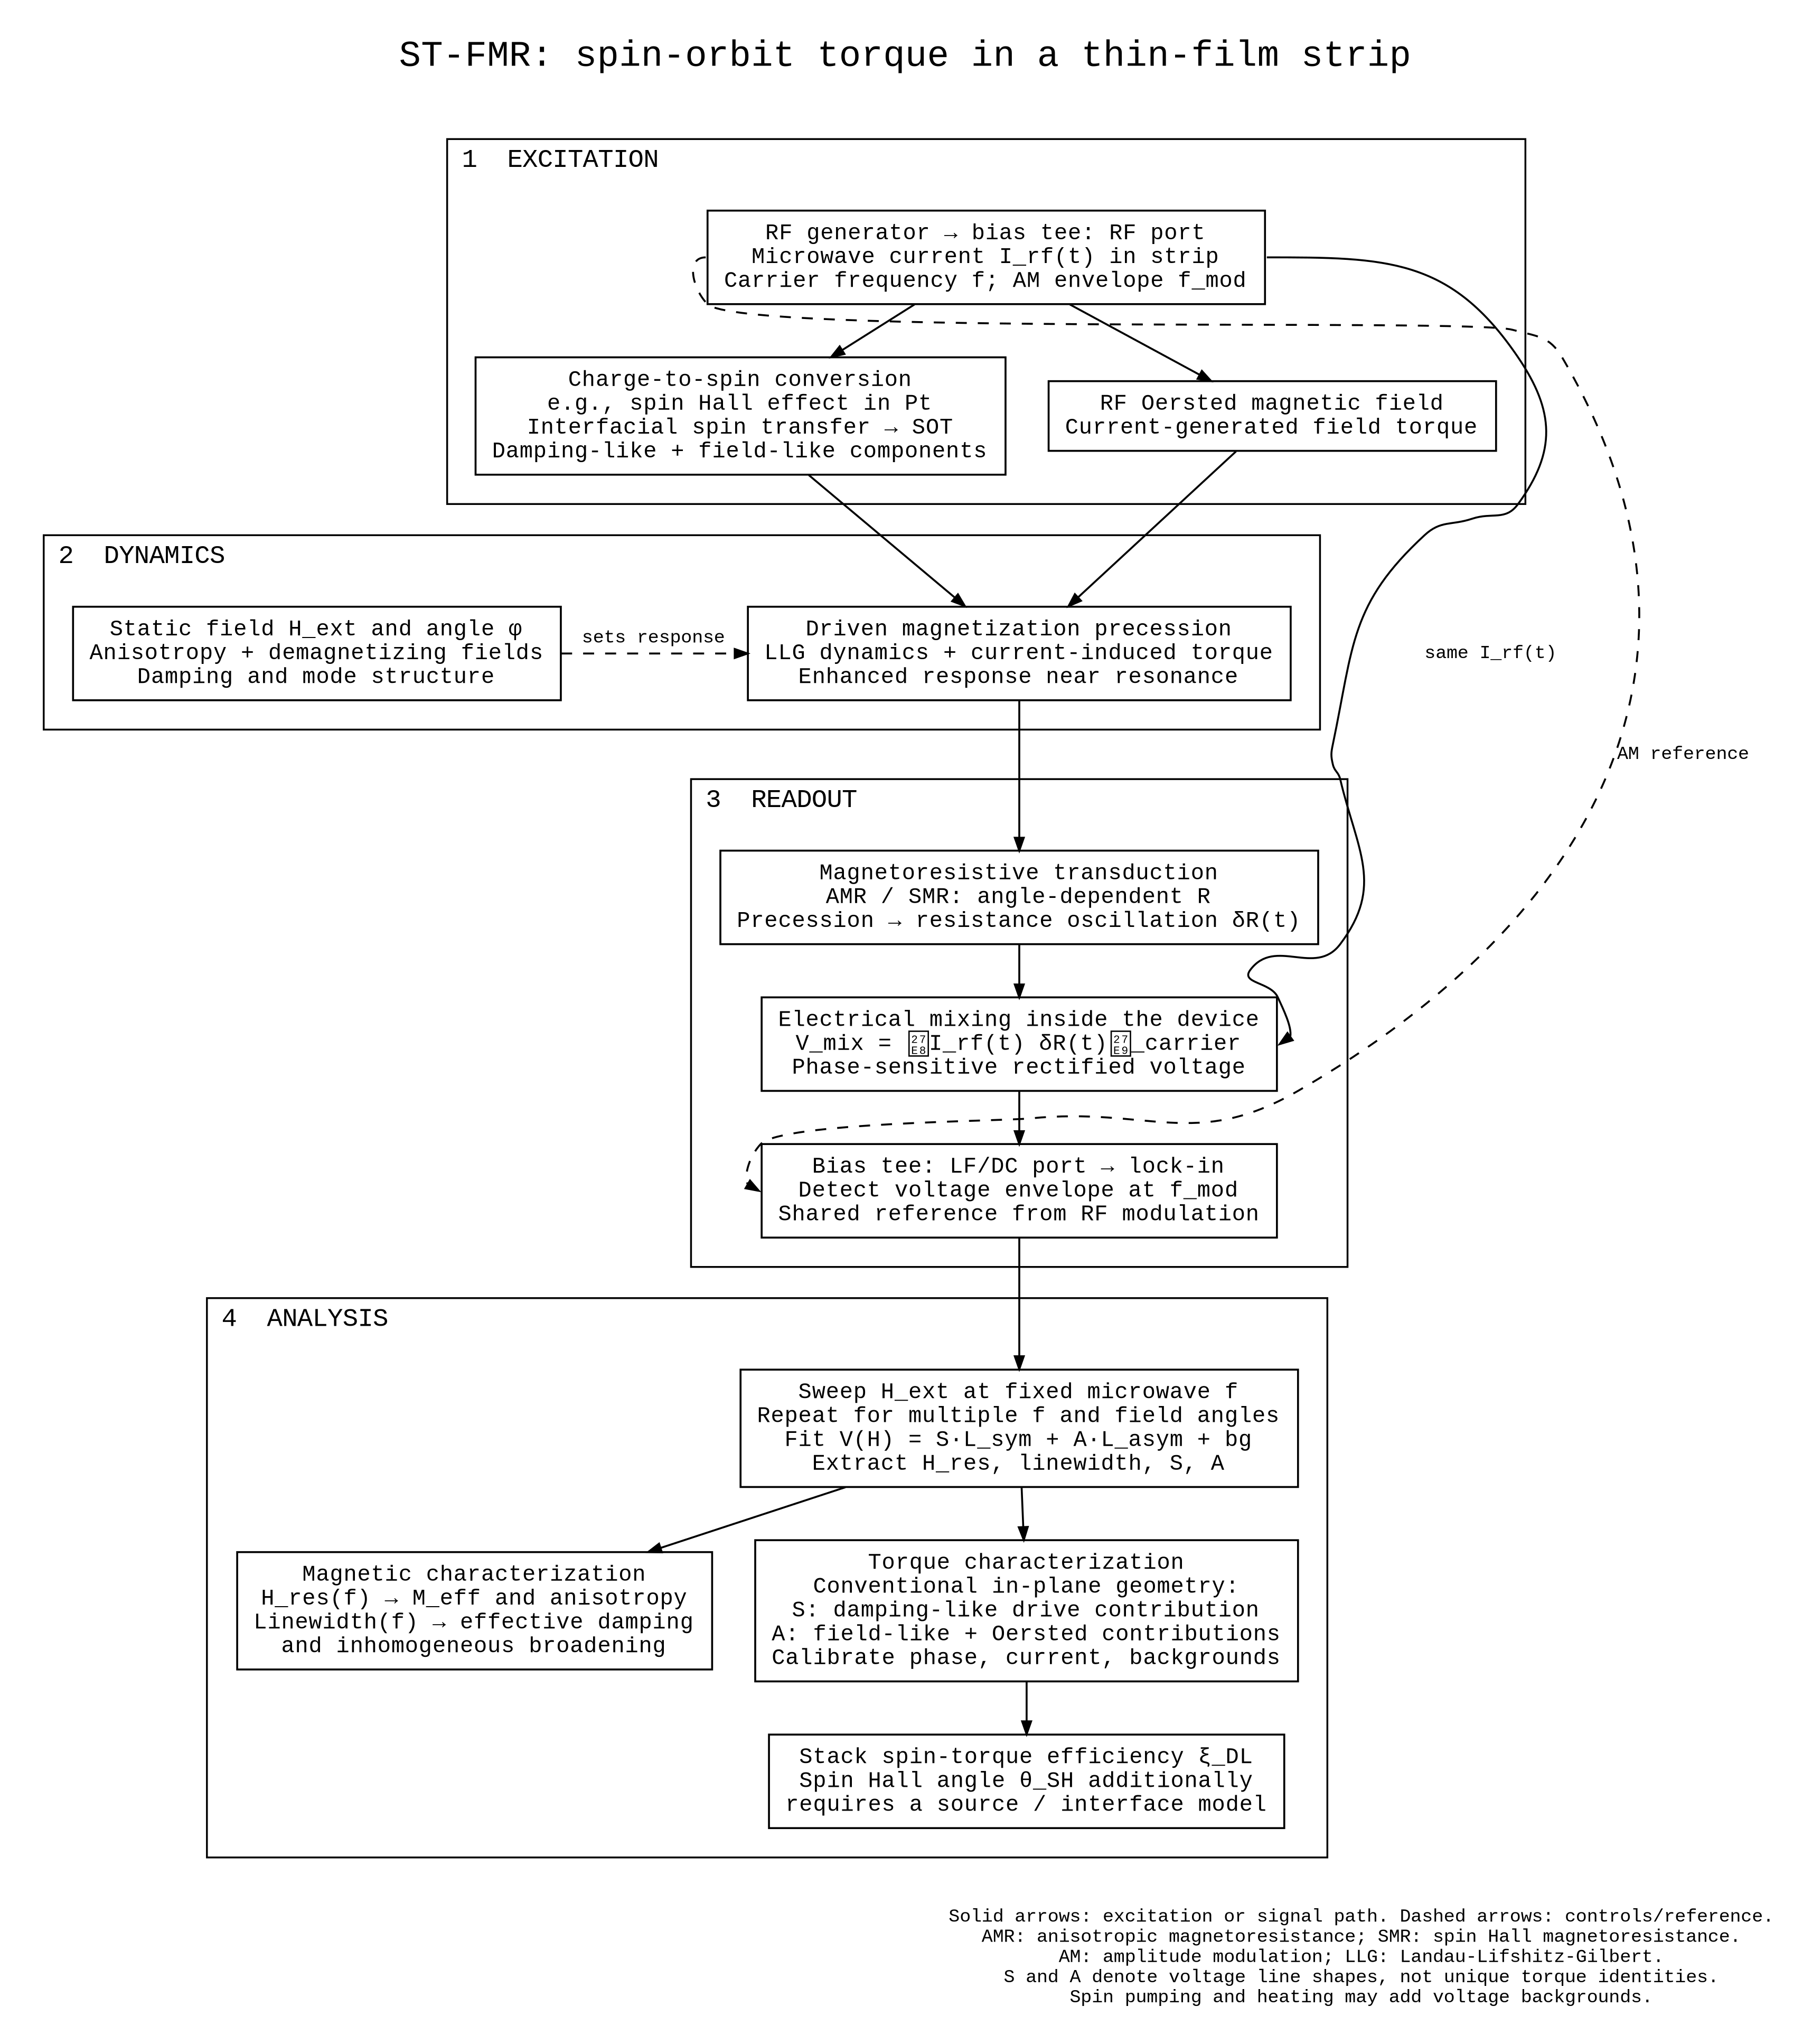

In [2]:
!uv pip install graphviz ipython

"""This script renders a monochrome ST-FMR mechanism and measurement flowchart.

Spin-torque ferromagnetic resonance (ST-FMR) is presented as a conceptual
flowchart rather than a circuit schematic or numerical model. The default
configuration describes conventional in-plane spin-orbit torque (SOT) driven
ST-FMR, while the magnetic tunnel junction (MTJ) setting describes
spin-transfer torque (STT) excitation and tunnel magnetoresistance (TMR)
readout. Amplitude modulation (AM) is detected at the envelope frequency.

References:
    Liu et al. (2011), https://doi.org/10.1103/PhysRevLett.106.036601
    Sankey et al. (2008), https://doi.org/10.1038/nphys783
    Goncalves et al. (2013), https://doi.org/10.1063/1.4826927
    Pai et al. (2015), https://doi.org/10.1103/PhysRevB.92.064426
    Zhang et al. (2019), https://doi.org/10.1103/PhysRevB.99.064424
"""

import textwrap
import graphviz
from IPython import display

# Control knobs
DEVICE_MODE = "sot"  # "sot": conducting strip; "mtj": magnetic tunnel junction.
GRAPH_DPI = 250
NODE_FONT = "DejaVu Sans"
NODE_FONT_SIZE = 12
TITLE_FONT_SIZE = 20
EDGE_FONT_SIZE = 10
NODE_SHAPE = "box"
EDGE_ROUTING = "spline"
RANK_DIRECTION = "TB"
BACKGROUND_COLOR = "white"
FOREGROUND_COLOR = "black"
MAX_CHARACTERS_PER_LINE = 42
NODE_SEPARATION = 0.32
RANK_SEPARATION = 0.38
LINE_WIDTH = 1.05
DISPLAY_WIDTH_PX = 1100


def wrap_text(text: str, max_width: int = MAX_CHARACTERS_PER_LINE) -> str:
    """Wraps each line of text while preserving explicit line breaks."""
    return "\n".join(
        textwrap.fill(
            line,
            width=max_width,
            break_long_words=False,
            break_on_hyphens=False,
        )
        for line in text.splitlines()
    )


def build_st_fmr_flowchart(mode: str = DEVICE_MODE) -> graphviz.Digraph:
    """Builds the selected ST-FMR excitation, mixing, and analysis pathways."""
    is_sot = mode == "sot"
    title = (
        "ST-FMR: spin-orbit torque in a thin-film strip"
        if is_sot
        else "ST-FMR: spin-transfer torque in a magnetic tunnel junction"
    )

    tree = graphviz.Digraph(name=f"st_fmr_{mode}", format="png")
    tree.attr(
        dpi=str(GRAPH_DPI),
        splines=EDGE_ROUTING,
        bgcolor=BACKGROUND_COLOR,
        color=FOREGROUND_COLOR,
        fontcolor=FOREGROUND_COLOR,
        fontname=NODE_FONT,
        rankdir=RANK_DIRECTION,
        nodesep=str(NODE_SEPARATION),
        ranksep=str(RANK_SEPARATION),
        pad="0.22",
        compound="true",
        newrank="true",
        labelloc="t",
        label=f"{title}\n ",
        fontsize=str(TITLE_FONT_SIZE),
    )
    tree.attr(
        "node",
        shape=NODE_SHAPE,
        style="solid",
        color=FOREGROUND_COLOR,
        fontcolor=FOREGROUND_COLOR,
        fontname=NODE_FONT,
        fontsize=str(NODE_FONT_SIZE),
        penwidth=str(LINE_WIDTH),
        margin="0.13,0.09",
    )
    tree.attr(
        "edge",
        color=FOREGROUND_COLOR,
        fontcolor=FOREGROUND_COLOR,
        arrowhead="normal",
        arrowsize="0.7",
        fontname=NODE_FONT,
        fontsize=str(EDGE_FONT_SIZE),
        penwidth=str(LINE_WIDTH),
    )

    with tree.subgraph(name="cluster_excitation") as stage:
        stage.attr(
            label="1  EXCITATION", labeljust="l", fontsize="14", margin="16"
        )
        current = (
            "RF generator → bias tee: RF port\n"
            "Microwave current I_rf(t) in strip\n"
            "Carrier frequency f; AM envelope f_mod"
            if is_sot
            else "RF generator → bias tee: RF port\n"
            "Microwave tunneling current I_rf(t)\n"
            "Carrier frequency f; AM envelope f_mod"
        )
        spin_drive = (
            "Charge-to-spin conversion\n"
            "e.g., spin Hall effect in Pt\n"
            "Interfacial spin transfer → SOT\n"
            "Damping-like + field-like components"
            if is_sot
            else "Spin-polarized tunneling current\n"
            "Reference layer polarizes current\n"
            "Spin transfer → torque on free layer\n"
            "In-plane + out-of-plane components"
        )
        stage.node("current", wrap_text(current))
        stage.node("spin_drive", wrap_text(spin_drive))
        stage.node(
            "field_drive",
            wrap_text("RF Oersted magnetic field\nCurrent-generated field torque"),
        )
        with stage.subgraph() as row:
            row.attr(rank="same")
            row.node("spin_drive")
            row.node("field_drive")
        stage.edge("current", "spin_drive")
        stage.edge("current", "field_drive")

    with tree.subgraph(name="cluster_dynamics") as stage:
        stage.attr(
            label="2  DYNAMICS", labeljust="l", fontsize="14", margin="16"
        )
        stage.node(
            "conditions",
            wrap_text(
                "Static field H_ext and angle φ\n"
                "Anisotropy + demagnetizing fields\n"
                "Damping and mode structure"
            ),
        )
        stage.node(
            "precession",
            wrap_text(
                "Driven magnetization precession\n"
                "LLG dynamics + current-induced torque\n"
                "Enhanced response near resonance"
            ),
        )
        with stage.subgraph() as row:
            row.attr(rank="same")
            row.node("conditions")
            row.node("precession")
        stage.edge("conditions", "precession", style="dashed", label="sets response")

    tree.edge("spin_drive", "precession")
    tree.edge("field_drive", "precession")

    with tree.subgraph(name="cluster_detection") as stage:
        stage.attr(
            label="3  READOUT", labeljust="l", fontsize="14", margin="16"
        )
        resistance = (
            "Magnetoresistive transduction\n"
            "AMR / SMR: angle-dependent R\n"
            "Precession → resistance oscillation δR(t)"
            if is_sot
            else "Tunnel magnetoresistive transduction\n"
            "TMR: R depends on relative layer angle\n"
            "Free-layer motion → oscillating δR(t)"
        )
        stage.node("resistance", wrap_text(resistance))
        stage.node(
            "mixing",
            wrap_text(
                "Electrical mixing inside the device\n"
                "V_mix = ⟨I_rf(t) δR(t)⟩_carrier\n"
                "Phase-sensitive rectified voltage"
            ),
        )
        stage.node(
            "readout",
            wrap_text(
                "Bias tee: LF/DC port → lock-in\n"
                "Detect voltage envelope at f_mod\n"
                "Shared reference from RF modulation"
            ),
        )
        stage.edge("resistance", "mixing")
        stage.edge("mixing", "readout")

    tree.edge("precession", "resistance")
    tree.edge(
        "current",
        "mixing",
        label="same I_rf(t)",
        constraint="false",
        tailport="e",
        headport="e",
    )
    tree.edge(
        "current",
        "readout",
        label="AM reference",
        style="dashed",
        constraint="false",
        tailport="w",
        headport="w",
    )

    with tree.subgraph(name="cluster_analysis") as stage:
        stage.attr(
            label="4  ANALYSIS", labeljust="l", fontsize="14", margin="16"
        )
        stage.node(
            "fit",
            wrap_text(
                "Sweep H_ext at fixed microwave f\n"
                "Repeat for multiple f and field angles\n"
                "Fit V(H) = S·L_sym + A·L_asym + bg\n"
                "Extract H_res, linewidth, S, A"
            ),
        )
        stage.node(
            "magnetic_output",
            wrap_text(
                "Magnetic characterization\n"
                "H_res(f) → M_eff and anisotropy\n"
                "Linewidth(f) → effective damping\n"
                "and inhomogeneous broadening"
            ),
        )
        torque_output = (
            "Torque characterization\n"
            "Conventional in-plane geometry:\n"
            "S: damping-like drive contribution\n"
            "A: field-like + Oersted contributions\n"
            "Calibrate phase, current, backgrounds"
            if is_sot
            else "Torque characterization\n"
            "Resolve torque vector with a\n"
            "geometry- and phase-aware model\n"
            "Bias dependence → torkance dτ/dV\n"
            "Calibrate current and backgrounds"
        )
        stage.node("torque_output", wrap_text(torque_output))
        stage.edge("fit", "magnetic_output")
        stage.edge("fit", "torque_output")
        with stage.subgraph() as row:
            row.attr(rank="same")
            row.node("magnetic_output")
            row.node("torque_output")
        if is_sot:
            stage.node(
                "efficiency",
                wrap_text(
                    "Stack spin-torque efficiency ξ_DL\n"
                    "Spin Hall angle θ_SH additionally\n"
                    "requires a source / interface model"
                ),
            )
            stage.edge("torque_output", "efficiency")

    tree.edge("readout", "fit")

    footer = (
        "Solid arrows: excitation or signal path. Dashed arrows: controls/reference.\n"
        "AMR: anisotropic magnetoresistance; SMR: spin Hall magnetoresistance.\n"
        "AM: amplitude modulation; LLG: Landau-Lifshitz-Gilbert.\n"
        "S and A denote voltage line shapes, not unique torque identities.\n"
        "Spin pumping and heating may add voltage backgrounds."
        if is_sot
        else "Solid arrows: excitation or signal path. Dashed arrows: controls/reference.\n"
        "TMR: tunnel magnetoresistance; AM: amplitude modulation.\n"
        "LLG: Landau-Lifshitz-Gilbert.\n"
        "Electric-field modulation of anisotropy is an additional possible MTJ drive."
    )
    tree.node("scope", footer, shape="plaintext", fontsize="10", margin="0.05")
    last_node = "efficiency" if is_sot else "torque_output"
    tree.edge(last_node, "scope", style="invis", weight="0")
    tree.edge("fit", "scope", style="invis", weight="80")
    return tree


if __name__ == "__main__":
    flowchart = build_st_fmr_flowchart(DEVICE_MODE)
    display.display(
        display.Image(data=flowchart.pipe(format="png"), width=DISPLAY_WIDTH_PX)
    )